Numerical variables before PCA: 10
PCA components retained: 7
Total explained variance: 96.75 %

Explained variance per component:
Component  Explained variance (%)
      PC1                   47.27
      PC2                   14.97
      PC3                   11.55
      PC4                    8.91
      PC5                    6.26
      PC6                    4.58
      PC7                    3.21


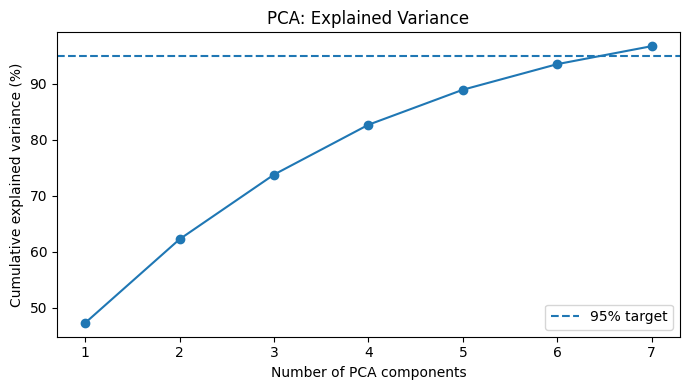


Logistic Regression after PCA
Accuracy: 70.05 %
Macro F1: 0.423
Majority-class baseline accuracy: 62.29 %

               precision    recall  f1-score   support

        huge       0.00      0.00      0.00         2
       large       0.52      0.30      0.38       109
      medium       0.53      0.45      0.48       205
       small       0.77      0.89      0.82       522

    accuracy                           0.70       838
   macro avg       0.45      0.41      0.42       838
weighted avg       0.68      0.70      0.68       838



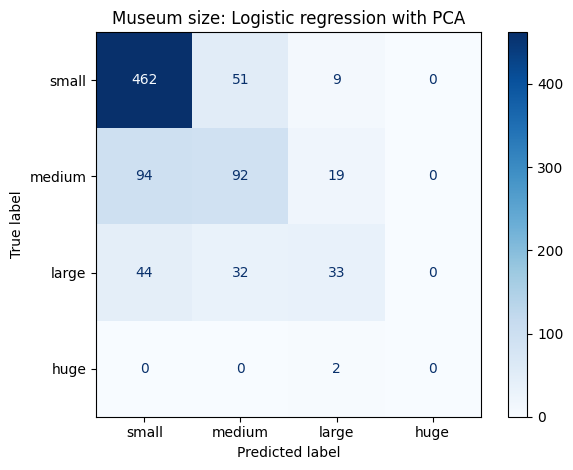

Predictions saved as pca_logistic_predictions.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

# Upload museums_cleaned.csv to Colab Files sidebar first.
df = pd.read_csv('museums_cleaned.csv')
df['country'] = df['admin_area'].astype('string').str.split('/').str[1].fillna('Unknown')
cat = ['governance', 'accreditation', 'subject_matter', 'country']
num = ['latitude', 'longitude', 'area_deprivation_index', 'area_deprivation_index_crime', 'area_deprivation_index_education', 'area_deprivation_index_employment', 'area_deprivation_index_health', 'area_deprivation_index_housing', 'area_deprivation_index_income', 'area_deprivation_index_services']
X = df[cat + num].copy()
for c in num:
    X[c] = pd.to_numeric(X[c], errors='coerce')
y = df['size']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, random_state=42, stratify=y)

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=.95))
])
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocess = ColumnTransformer([
    ('numerical_pca', numeric_pipeline, num),
    ('categorical', cat_pipeline, cat)
])
model = Pipeline([
    ('preprocess', preprocess),
    ('logistic', LogisticRegression(max_iter=3000))
])
model.fit(X_train, y_train)
pca = model.named_steps['preprocess'].named_transformers_['numerical_pca'].named_steps['pca']
print('Numerical variables before PCA:', len(num))
print('PCA components retained:', pca.n_components_)
print('Total explained variance:', round(pca.explained_variance_ratio_.sum()*100, 2), '%')

var_table = pd.DataFrame({'Component': [f'PC{i+1}' for i in range(pca.n_components_)], 'Explained variance (%)': (pca.explained_variance_ratio_*100).round(2)})
print('\nExplained variance per component:')
print(var_table.to_string(index=False))

plt.figure(figsize=(7,4))
plt.plot(range(1, pca.n_components_+1), np.cumsum(pca.explained_variance_ratio_)*100, marker='o')
plt.axhline(95, linestyle='--', label='95% target')
plt.xlabel('Number of PCA components')
plt.ylabel('Cumulative explained variance (%)')
plt.title('PCA: Explained Variance')
plt.legend()
plt.tight_layout()
plt.show()

pred = model.predict(X_test)
print('\nLogistic Regression after PCA')
print('Accuracy:', round(accuracy_score(y_test,pred)*100,2),'%')
print('Macro F1:', round(f1_score(y_test,pred,average='macro',zero_division=0),3))
print('Majority-class baseline accuracy:', round((y_test == y_train.mode()[0]).mean()*100,2),'%')
print('\n',classification_report(y_test,pred,zero_division=0))
labels = ['small','medium','large','huge']
ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=labels,cmap='Blues',values_format='d')
plt.title('Museum size: Logistic regression with PCA')
plt.tight_layout()
plt.show()

pd.DataFrame({'actual_size':y_test.to_numpy(),'predicted_size':pred}).to_csv('pca_logistic_predictions.csv',index=False)
print('Predictions saved as pca_logistic_predictions.csv')
